# 1. Imports

In [1]:
import torch
import torchvision
import torchvision.transforms as transforms
import torch.nn as nn

import matplotlib.pyplot as plt
import numpy as np

# 2. Variables

In [53]:
batch_size = 64
num_classes = 10
img_size = 28
patch_size = 7
num_channels = 1
num_patches = (img_size // patch_size) ** 2
num_heads = 1
embed_dim = 16
mlp_dim = 16
transformer_units = 1
learning_rate = 0.001
epochs = 10

In [36]:
transform = transforms.Compose(
    [transforms.ToTensor()]
)

# 3. Load Dataset

In [26]:
train_dataset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
val_dataset = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)

# 4. Create train and val batches

In [27]:
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

In [28]:
# visualize batch size
images, labels = next(iter(train_loader))

print(images.shape, labels.shape)

torch.Size([64, 1, 28, 28]) torch.Size([64])


# 5. Define PatchEmbedding Class

In [37]:
class PatchEmbedding(nn.Module):
    def __init__(self):
        super().__init__()
        self.patch_embed = nn.Conv2d(
            in_channels=num_channels,
            out_channels=embed_dim,
            kernel_size=patch_size,
            stride=patch_size
        )

    def forward(self, x):
        x = self.patch_embed(x)     # [64, 20, 4, 4]
        x = x.flatten(2)            # [64, 20, 16]
        x = x.transpose(1, 2)       # [batch_size, patch_size, embed_dim][64, 16, 20]
        return x

In [38]:
images, labels = next(iter(train_loader))
patchEmbed = PatchEmbedding()
result = patchEmbed.forward(images)

print(f"Images before patch embedding: {images.shape}")
print(f"Images after patch embedding: {result.shape}")

Images before patch embedding: torch.Size([64, 1, 28, 28])
Images after patch embedding: torch.Size([64, 16, 16])


# 6. Define Transformer Encoder Class

In [39]:
# LayerNormalization
# MultiHeadAttention
# LayerNormalization
# Residuals
# MLP - Activation Function

class TransformerArchitecture(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_norm1 = nn.LayerNorm(embed_dim)
        self.self_attention = nn.MultiheadAttention(embed_dim, num_heads, batch_first=True)
        self.layer_norm2 = nn.LayerNorm(embed_dim)
        self.mlp = nn.Sequential(
            nn.Linear(embed_dim, mlp_dim),
            nn.GELU(),
            nn.Linear(mlp_dim, embed_dim),
        )

    def forward(self, x):
        residual1 = x
        attention_output = self.self_attention(self.layer_norm1(x), self.layer_norm1(x), self.layer_norm1(x))[0] # calculate k, q, v
        x = attention_output + residual1
        residual2 = x
        mlp_output = self.mlp(self.layer_norm2(x))
        x = mlp_output + residual2
        return x

# 8. Define the Vision Transformer Class

In [43]:
class VisionTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.patch_embedding = PatchEmbedding()
        self.cls_token = nn.Parameter(torch.randn(1, 1, embed_dim))
        self.position_embedding = nn.Parameter(torch.randn(1, (img_size // patch_size) ** 2 + 1, embed_dim))
        self.transformer_blocks = nn.Sequential(*[TransformerArchitecture() for _ in range(transformer_units)]) # Number of transformers blocks
        
        self.mlp = nn.Sequential(
            nn.LayerNorm(embed_dim),
            nn.Linear(embed_dim, num_classes)
        )

    def forward(self, x):
        x = self.patch_embedding(x)
        B = x.size(0)

        cls_tokens = self.cls_token.expand(B, -1, -1)
        x = torch.cat((cls_tokens, x), dim=1)
        x = x + self.position_embedding
        x = self.transformer_blocks(x)
        x = x[:,0]
        x = self.mlp(x)
        return x

# 9. Train

In [44]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model = VisionTransformer().to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
criterion = nn.CrossEntropyLoss()

In [54]:
for epoch in range(epochs):
    total_loss = 0
    total_epoch = 0
    correct_epoch = 0

    model.train()
    for batch_idx, (images, labels) in enumerate(train_loader):
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)

        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        preds = outputs.argmax(dim=1)

        correct = (preds == labels).sum().item()
        accuracy = correct / labels.size(0)

        correct_epoch += correct
        total_epoch += labels.size(0)

    epoch_acc = correct_epoch / total_epoch
    print(f"Epoch [{epoch+1}]: Total Loss = {total_loss:.4f} | Accuracy = {epoch_acc:.4f}")

Epoch [1]: Total Loss = 429.3312 | Accuracy = 0.8561
Epoch [2]: Total Loss = 408.2455 | Accuracy = 0.8629
Epoch [3]: Total Loss = 386.8715 | Accuracy = 0.8703
Epoch [4]: Total Loss = 370.9571 | Accuracy = 0.8746
Epoch [5]: Total Loss = 360.3503 | Accuracy = 0.8780
Epoch [6]: Total Loss = 348.6075 | Accuracy = 0.8835
Epoch [7]: Total Loss = 339.2210 | Accuracy = 0.8867
Epoch [8]: Total Loss = 329.4448 | Accuracy = 0.8893
Epoch [9]: Total Loss = 329.9348 | Accuracy = 0.8896
Epoch [10]: Total Loss = 320.6205 | Accuracy = 0.8928


# 10. Evaluate

In [55]:
correct = 0
total = 0

model.eval()
with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

test_acc = correct / total
print(f"Val Accuracy: {test_acc:.4f}")

Val Accuracy: 0.8953


# 11. Inference

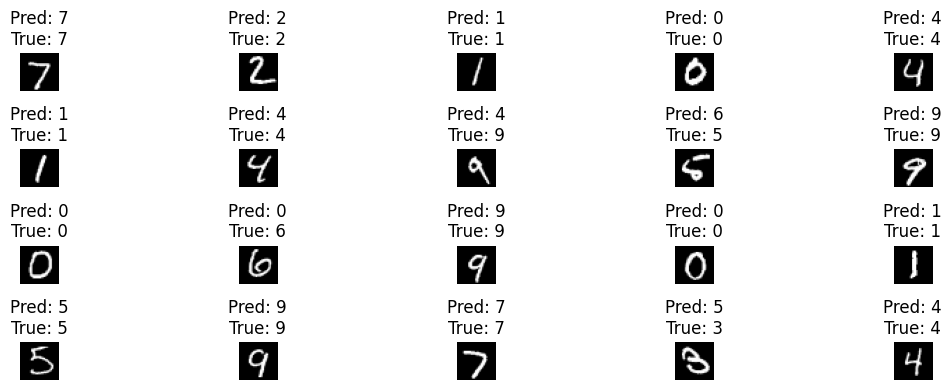

In [56]:
model.eval()
images, labels = next(iter(val_loader))
images, labels = images.to(device), labels.to(device)

with torch.no_grad():
    outputs = model(images)
    preds = outputs.argmax(dim=1)

plt.figure(figsize=(12, 4))
for i in range(20):
    plt.subplot(4, 5, i+1)
    plt.imshow(images[i].squeeze(), cmap='gray')
    plt.title(f"Pred: {preds[i].item()}\nTrue: {labels[i].item()}")
    plt.axis('off')

plt.tight_layout()
plt.show()